# Chapter 01: Quantifying Uncertainty — Python Laboratory
### *Shannon Entropy, The Binary Curve, and The Beta-Binomial Conjugate Engine*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Prev: Ch 00: The Physics of Belief (Python)](00_the_physics_of_belief.ipynb) | [Next: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement from scratch:
1. **The Binary Entropy Function** $H_2(\theta)$ and verify its physical properties.
2. **The Beta-Binomial Conjugate Updating Engine**: Updating prior beliefs about test flakiness with streaming CI run observations.
3. **Differential Entropy Tracking**: Calculating the exact bits of uncertainty resolved as a function of the number of test runs $N$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
from scipy.special import betaln, psi

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Implementation: The Binary Entropy Function $H_2(\theta)$

We write a vectorized function computing $H_2(\theta)$ with safe $0\log_2(0) = 0$ boundary handling.


In [2]:
def binary_entropy(theta):
    # Vectorized binary Shannon entropy in bits
    theta = np.asarray(theta, dtype=np.float64)
    # Clip to avoid log(0) while maintaining continuity
    eps = 1e-15
    theta_safe = np.clip(theta, eps, 1.0 - eps)
    h = -theta_safe * np.log2(theta_safe) - (1.0 - theta_safe) * np.log2(1.0 - theta_safe)
    # Force exact 0 at boundaries
    h = np.where((theta == 0.0) | (theta == 1.0), 0.0, h)
    return h

test_thetas = [0.0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1.0]
print("=" * 55)
print(f"{'Failure Rate theta':<22} | {'Binary Entropy H2 (Bits)':<25}")
print("=" * 55)
for t in test_thetas:
    print(f"{t:<22.2f} | {binary_entropy(t):<25.4f}")
print("=" * 55)


Failure Rate theta     | Binary Entropy H2 (Bits) 
0.00                   | 0.0000                   
0.01                   | 0.0808                   
0.05                   | 0.2864                   
0.10                   | 0.4690                   
0.25                   | 0.8113                   
0.50                   | 1.0000                   
0.75                   | 0.8113                   
0.90                   | 0.4690                   
0.99                   | 0.0808                   
1.00                   | 0.0000                   


---

## 3. Implementation: Beta Differential Entropy in Bits

To measure our ignorance about the continuous parameter $\theta \sim \text{Beta}(\alpha, \beta)$, we implement the exact analytical differential entropy in bits:
$$h_{\text{bits}}(\theta) = \frac{1}{\ln 2} \left[ \ln \text{B}(\alpha, \beta) - (\alpha - 1)\psi(\alpha) - (\beta - 1)\psi(\beta) + (\alpha + \beta - 2)\psi(\alpha + \beta) \right]$$


In [3]:
def beta_entropy_bits(alpha, beta):
    # Computes differential entropy of Beta(alpha, beta) in bits
    alpha = float(alpha)
    beta = float(beta)
    ln_b = betaln(alpha, beta)
    term1 = (alpha - 1.0) * psi(alpha)
    term2 = (beta - 1.0) * psi(beta)
    term3 = (alpha + beta - 2.0) * psi(alpha + beta)
    h_nats = ln_b - term1 - term2 + term3
    return h_nats / np.log(2.0)

print(f"Entropy of Beta(1, 1) [Flat Uniform Prior]:      {beta_entropy_bits(1, 1):.4f} bits (Max ignorance)")
print(f"Entropy of Beta(2, 8) [Weakly Informative]:       {beta_entropy_bits(2, 8):.4f} bits")
print(f"Entropy of Beta(10, 90) [100 runs evidence]:      {beta_entropy_bits(10, 90):.4f} bits")
print(f"Entropy of Beta(100, 900) [1000 runs evidence]:   {beta_entropy_bits(100, 900):.4f} bits (Sharp knowledge)")


Entropy of Beta(1, 1) [Flat Uniform Prior]:      0.0000 bits (Max ignorance)
Entropy of Beta(2, 8) [Weakly Informative]:       -1.1468 bits
Entropy of Beta(10, 90) [100 runs evidence]:      -3.0544 bits
Entropy of Beta(100, 900) [1000 runs evidence]:   -4.6769 bits (Sharp knowledge)


---

## 4. Simulation: Simulating a Flaky Test in CI & Sequential Bayesian Updating

We simulate a test with true flakiness rate $\theta_{\text{true}} = 0.08$ (fails $8\%$ of the time).
We start from an uninformative prior $\text{Beta}(1, 1)$ and observe sequential runs across $N = [0, 2, 10, 50, 250]$.


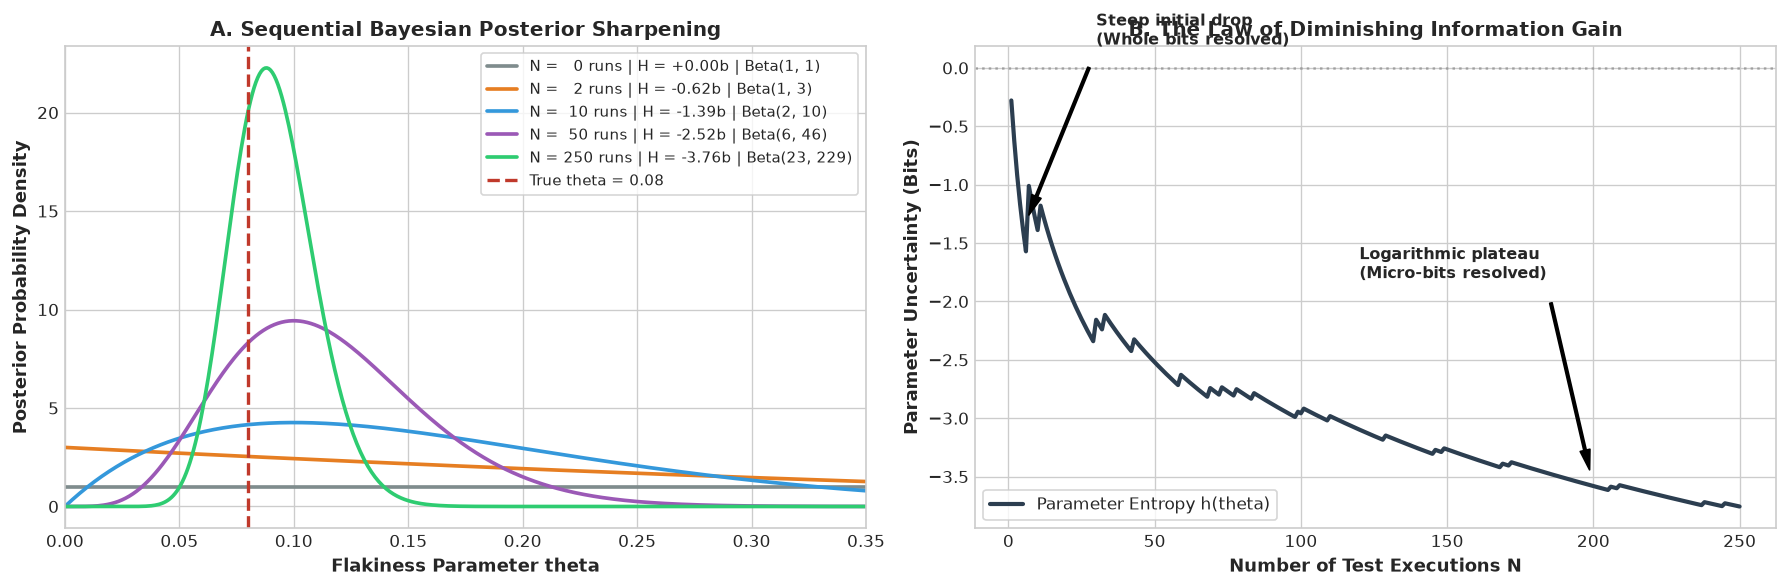

In [4]:
np.random.seed(42)
theta_true = 0.08
num_runs = 250
# Generate synthetic test execution history (1 = Fail, 0 = Pass)
test_runs = (np.random.uniform(0, 1, size=num_runs) < theta_true).astype(int)

# Checkpoints to visualize
checkpoints = [0, 2, 10, 50, 250]
posteriors = []

alpha_0, beta_0 = 1.0, 1.0  # Prior

for cp in checkpoints:
    if cp == 0:
        a_post, b_post = alpha_0, beta_0
    else:
        k = np.sum(test_runs[:cp])
        a_post = alpha_0 + k
        b_post = beta_0 + (cp - k)
    h_bits = beta_entropy_bits(a_post, b_post)
    posteriors.append((cp, a_post, b_post, h_bits))

theta_grid = np.linspace(0.0001, 0.40, 500)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Posterior Density Sharpening
colors = ['#7f8c8d', '#e67e22', '#3498db', '#9b59b6', '#2ecc71']
for (cp, a, b, h), c in zip(posteriors, colors):
    pdf = beta_dist.pdf(theta_grid, a, b)
    label = f"N = {cp:3d} runs | H = {h:+5.2f}b | Beta({int(a)}, {int(b)})"
    axes[0].plot(theta_grid, pdf, lw=2.2, color=c, label=label)

axes[0].axvline(theta_true, color='#c0392b', ls='--', lw=2.0, label=f"True theta = {theta_true:.2f}")
axes[0].set_xlabel("Flakiness Parameter theta", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Posterior Probability Density", fontsize=11, fontweight='bold')
axes[0].set_title("A. Sequential Bayesian Posterior Sharpening", fontsize=12, fontweight='bold')
axes[0].set_xlim(0, 0.35)
axes[0].legend(frameon=True, fontsize=9)

# Panel 2: Entropy Decay vs Number of Runs
n_range = np.arange(1, 251)
cum_failures = np.cumsum(test_runs)
cum_passes = n_range - cum_failures

entropy_curve = [beta_entropy_bits(alpha_0 + k, beta_0 + p) for k, p in zip(cum_failures, cum_passes)]

axes[1].plot(n_range, entropy_curve, color='#2c3e50', lw=2.5, label='Parameter Entropy h(theta)')
axes[1].axhline(0, color='gray', ls=':', alpha=0.6)
axes[1].set_xlabel("Number of Test Executions N", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Parameter Uncertainty (Bits)", fontsize=11, fontweight='bold')
axes[1].set_title("B. The Law of Diminishing Information Gain", fontsize=12, fontweight='bold')

# Annotate steep drop
axes[1].annotate("Steep initial drop\n(Whole bits resolved)", xy=(5, entropy_curve[4]), xytext=(30, 0.2),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
axes[1].annotate("Logarithmic plateau\n(Micro-bits resolved)", xy=(200, entropy_curve[199]), xytext=(120, -1.8),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


---

## 5. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Entropy Calculation
1. Compute the binary entropy $H_2(\theta)$ for a test with $\theta = 0.05$ (fails $5\%$ of the time).
2. How many bits of entropy does a single run produce?
3. What is the expected failure rate for a test with prior $\text{Beta}(2, 98)$ after observing $1$ failure in $10$ runs?

### Tier 2: Intermediate — Prior Sensitivity Analysis
Compare two engineering teams analyzing the exact same test outcome: **$1$ failure in $20$ runs**.
* **Team A (Skeptical)**: Uses prior $\text{Beta}(1, 99)$ (assumes tests are generally solid).
* **Team B (Agnostic)**: Uses prior $\text{Beta}(1, 1)$ (assumes nothing).
Calculate the posterior mean, 95% credible interval, and posterior entropy for both teams.

### Tier 3: Advanced Research — The Information Stopping Rule
Write an automated function `run_test_until_certain(theta_true, target_entropy_reduction=2.0)` that executes simulated CI runs one-by-one.
* It stops running tests as soon as the total parameter entropy has dropped by $2.0\text{ bits}$ from the prior.
* Plot the distribution of required test runs $N_{\text{stop}}$ across 1,000 Monte Carlo trials.


In [5]:
# Solution verification for Tier 1:
h_05 = binary_entropy(0.05)
# Prior Beta(2, 98) with k=1, N=10:
alpha_post = 2 + 1
beta_post = 98 + (10 - 1)
expected_theta = alpha_post / (alpha_post + beta_post)

print("Tier 1 Solutions:")
print(f"1. Binary entropy for theta = 0.05:          {h_05:.4f} bits")
print(f"2. Prior Beta(2, 98) + 1 fail in 10 runs:")
print(f"   Updated alpha: {alpha_post}, Updated beta: {beta_post}")
print(f"   Posterior Expected Failure Rate:          {expected_theta:.4f} ({expected_theta*100:.2f}%)")


Tier 1 Solutions:
1. Binary entropy for theta = 0.05:          0.2864 bits
2. Prior Beta(2, 98) + 1 fail in 10 runs:
   Updated alpha: 3, Updated beta: 107
   Posterior Expected Failure Rate:          0.0273 (2.73%)


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Prev: Ch 00: The Physics of Belief (Python)](00_the_physics_of_belief.ipynb) | [Next: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb)**
